# Finance-IDC — Comprehensive Exploratory Data Analysis, System Architecture & Machine Learning Audit

**Project:** Does financial-news sentiment help forecast the next NIFTY 50 session?  
**Repository:** <https://github.com/SVDKWTD/finance-IDC>  
**Course Context:** IDC409, Topic 3 — Web Scraping I (Finance + News)

---

## 1. Executive Summary & Step-by-Step Project Walkthrough

This notebook documents the end-to-end architecture, data collection, cleaning operations, feature engineering, and modeling experiments for the **Finance-IDC** project.

### Step-by-Step Operational Overview:

#### A. Main Inline Production Pipeline
1. **Multi-Asset Price Scraper (`collect_prices.py`):** Automatically fetches daily OHLCV prices from Yahoo Finance for the target index (`^NSEI` NIFTY 50) and three macro context assets: Gold (`GC=F`), Brent Crude (`BZ=F`), and USD/INR (`INR=X`). It handles overlap lookbacks to capture late exchange adjustments.
2. **Rolling RSS News Collector (`collect_recent_news.py` & `backfill_historical_news.py`):** Collects news headlines across 10 strategic Google News RSS search queries. Applies fuzzy string normalization and publication date de-duplication to prevent duplicate syndicated stories. Automatically tags 2026 incoming news to the target `nifty` asset.
3. **SQLite Data Warehouse Ingestion (`import_collected_data.py`):** Merges historical (2021–2025) and active (2026) headline collections into an SQLite database (`data/market.db`), enforcing primary key constraints on `(url, market)` and preventing `unclassified` tag leakage.
4. **Market Session Alignment (`align_news_market.py`):** Converts headline publication timestamps to Indian Standard Time (IST) and assigns each headline to its corresponding trading session using strict cutoff rules:
   * **NIFTY cutoff:** 15:45 IST (15 minutes post-market close). Headlines after 15:45 IST roll to session $t+1$.
   * **USD/INR & Commodities cutoffs:** 17:00 IST / 00:00 IST respectively.
5. **Tri-Scorer Ensemble Sentiment Engine (`analyze_news_sentiment.py`):** Scores unique headlines using an ensemble of three models:
   * **FinBERT (`ProsusAI/finbert`):** Domain-specific transformer model calculating financial probability scores: $\text{FinBERT Score} = P(\text{Positive}) - P(\text{Negative})$.
   * **VADER (`SentimentIntensityAnalyzer`):** Rule-based lexicon model calculating compound polarity.
   * **TextBlob:** Pattern-based polarity score.
   * **Ensemble Score:** Equal-weighted mean of all three scores: $\frac{1}{3} (\text{FinBERT} + \text{VADER} + \text{TextBlob})$.
6. **Per-Session Dynamic Sampling (`build_sampled_dataset.py`):** Caps daily 2026 headlines to a maximum of $N=25$ headlines per trading session to match historical density (2021–2025) and prevent density regime leakage.
7. **Official Next-Session Forecast Engine (`generate_forecast.py`):** Trains an expanding-window Ridge regression and Logistic Classifier pipeline on engineered lag, momentum, and sentiment features to issue next-session predictions.

#### B. Side-Hustle Experiments & Diagnostic Studies
* **PCA Dimensionality Reduction Study:** Evaluating whether compressing high-dimensional sentiment and market feature sets into orthogonal principal components eliminates noise and multicollinearity.
* **Feature Ablation Experiment:** Comparing prediction performance across 4 distinct feature subsets (Market-Only, Market+Volume, Market+Sentiment, Full Corpus).
* **Volatility Regime Model:** Building a trailing 252-session quantile volatility classifier to predict whether next-day return magnitude $|r_{t+1}|$ will breach the 80th percentile threshold.
* **Walk-Forward Evaluation Mechanics:** Simulating real-time trading operations by training strictly on sessions $0 \dots t-1$ to predict session $t$, walking forward across 433 out-of-sample sessions.

---

### Table of Contents
| Part | Topic |
|---|---|
| A | Environment Setup & Production Imports |
| B | Multi-Layer Data Inventory & Schema Verification |
| C | Raw NIFTY 50 Quality Checks, Data Cleaning & Closing Price Distributions |
| D | External Macro Markets (Gold, Brent Crude, USD/INR) & Cross-Asset Correlations |
| E | News Headline Archive Density Shifts & Timestamp Placeholder Diagnostics |
| F | Market Session Alignment, IST Cutoffs & Intraday Leakage Audit |
| G | Sentiment Analysis — Tri-Scorer Agreement & Distribution Evaluation |
| H | Feature Engineering — Stationarity, Log-Volume & Multicollinearity (VIF) |
| I | Target Construction — Returns, Direction & Volatility Regimes |
| J | Descriptive News-to-Market Relationships & Cross-Correlation |
| K | Walk-Forward Mechanics & Machine Learning Algorithm Benchmarks |
| L | Side Experiments: Feature Ablation & PCA Dimensionality Reduction |
| M | Summary Findings & Architectural Recommendations |

## Part A — Environment Setup & Production Imports

In [2]:
import warnings, sys, json, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 140,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

ROOT = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent)
            if (p / "data" / "raw").exists())
RAW, PROC, SRC = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "src"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))

BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2a6fdb", "#e8833a", "#3a9d5d", "#d64545", "#7a7a7a", "#8e44ad"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

print("Project Root:", ROOT)
print("Pandas Version:", pd.__version__, "| NumPy Version:", np.__version__)

Project Root: C:\Users\surya\Documents\finance-IDC-Project
Pandas Version: 3.1.0 | NumPy Version: 2.5.4


---
## Part B — Data Inventory & Multi-Layer System Overview

The system architecture organizes data into four clean operational tiers:
1. **Raw Tier (`data/raw/`):** Immutable scraped price CSVs and raw RSS headline exports.
2. **Database Tier (`data/market.db`):** Relational SQLite storage providing primary key integrity.
3. **Processed Tier (`data/processed/`):** Aligned sessions, ensemble sentiment scores, and daily aggregates.
4. **Model Dataset Tier (`data/processed/model_dataset_sampled_monthly_2026.csv`):** Per-session sampled feature tables ready for scikit-learn model pipelines.

In [3]:
inventory = [
    ("raw/nifty50_prices.csv",         "NIFTY 50 daily OHLCV from yfinance (^NSEI)",            "Date"),
    ("raw/gold_prices.csv",            "Gold futures (GC=F)",                                    "Date"),
    ("raw/usd_inr_prices.csv",        "USD/INR (INR=X)",                                        "Date"),
    ("raw/brent_prices.csv",          "Brent crude futures (BZ=F)",                             "Date"),
    ("raw/historical_news_2021_2025.csv", "Headlines 2021-2025, Google News RSS",              "published_at"),
    ("raw/recent_news_2026.csv",      "Headlines 2026, rolling incremental collector",           "published_at"),
    ("processed/nifty50_processed.csv", "Cleaned NIFTY prices + returns",                       "Date"),
    ("processed/news_market_alignment.csv", "Headline-to-session alignment",                    "feature_date"),
    ("processed/news_sentiment_scored.csv", "Headline sentiment (FinBERT + VADER + TextBlob)",  "feature_date"),
    ("processed/news_sentiment_daily.csv",  "Daily sentiment aggregates (NIFTY-filtered)",        "date"),
    ("processed/news_market_daily.csv",     "Daily prices + external returns + counts",          "date"),
    ("processed/model_dataset_sampled_monthly_2026.csv", "OFFICIAL sampled model dataset",     "date"),
]

rows = []
for rel, role, dc in inventory:
    path = ROOT / "data" / rel
    if path.exists():
        d = pd.read_csv(path)
        s = (pd.to_datetime(d[dc], utc=True, format="mixed", errors="coerce")
             if dc == "published_at" else pd.to_datetime(d[dc], errors="coerce"))
        rows.append({"file": rel, "role": role, "rows": len(d), "cols": d.shape[1],
                     "first_date": str(s.min())[:10], "last_date": str(s.max())[:10]})

inv = pd.DataFrame(rows)
display(inv)

,file,role,rows,cols,first_date,last_date
0,raw/nifty50_prices.csv,NIFTY 50 daily OHLCV from yfinance (^NSEI),1443,8,2021-01-01,2026-11-04
1,raw/gold_prices.csv,Gold futures (GC=F),1470,7,2021-01-04,2026-11-04
2,raw/usd_inr_prices.csv,USD/INR (INR=X),1519,7,2021-01-01,2026-11-04
3,raw/brent_prices.csv,Brent crude futures (BZ=F),1470,7,2021-01-04,2026-11-04
4,raw/historical_news_2021_2025.csv,"Headlines 2021-2025, Google News RSS",5581,9,2021-01-01,2025-12-31
5,raw/recent_news_2026.csv,"Headlines 2026, rolling incremental collector",7785,9,2026-01-01,2026-11-05
6,processed/nifty50_processed.csv,Cleaned NIFTY prices + returns,1443,11,2021-01-01,2026-11-04
7,processed/news_market_alignment.csv,Headline-to-session alignment,13151,9,2021-01-01,2026-11-04
8,processed/news_sentiment_scored.csv,Headline sentiment (FinBERT + VADER + TextBlob),13116,18,2021-01-01,2026-11-04
9,processed/news_sentiment_daily.csv,Daily sentiment aggregates (NIFTY-filtered),1056,10,2021-01-01,2026-11-04


---
## Part C — Raw NIFTY 50 Quality Checks, Data Cleaning & Price Distribution Diagnostics

### Detailed Cleaning Operations & Rules:
1. **Zero/Incomplete Bar Removal:** The scraper drops incomplete intraday rows where `Close` is NaN or $\le 0$.
2. **De-duplication:** Sorts chronologically by `Date` and retains the last bar to incorporate exchange settlements.
3. **Return Computation:** Computes daily percentage returns: $r_t = 100 \times \left( \frac{\text{Close}_t}{\text{Close}_{t-1}} - 1 \right)$.

,Count
Total Rows in Raw File,1443
Unparseable Dates,0
Duplicate Dates,0
Missing Close Prices,0
Non-Positive Close Prices,0
Volume == 0 Count,12
OHLC High Violations,0
OHLC Low Violations,0


Mean Daily Return: 0.0411% | Standard Deviation: 0.8897% | Excess Kurtosis: 3.6415


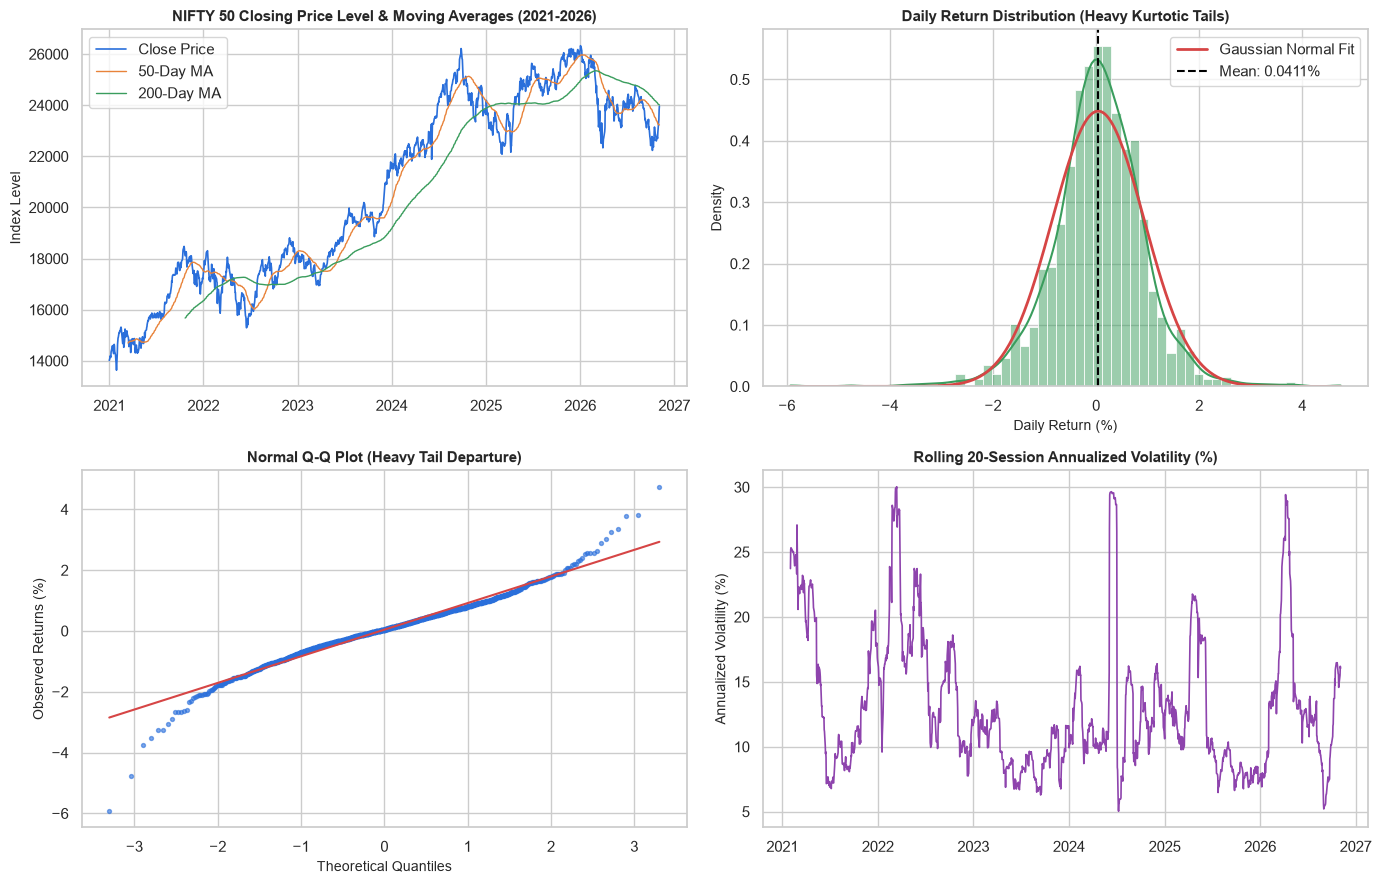

In [6]:
nifty_raw = pd.read_csv(RAW / "nifty50_prices.csv")
nifty_raw["Date"] = pd.to_datetime(nifty_raw["Date"], errors="coerce")

# Quality Diagnostics
ohlc_bad_high = (nifty_raw["High"] < nifty_raw[["Open", "Close", "Low"]].max(axis=1) - 1e-9)
ohlc_bad_low  = (nifty_raw["Low"]  > nifty_raw[["Open", "Close", "High"]].min(axis=1) + 1e-9)

checks = pd.Series({
    "Total Rows in Raw File": len(nifty_raw),
    "Unparseable Dates": int(nifty_raw["Date"].isna().sum()),
    "Duplicate Dates": int(nifty_raw["Date"].duplicated().sum()),
    "Missing Close Prices": int(nifty_raw["Close"].isna().sum()),
    "Non-Positive Close Prices": int((nifty_raw["Close"] <= 0).sum()),
    "Volume == 0 Count": int((nifty_raw["Volume"] == 0).sum()),
    "OHLC High Violations": int(ohlc_bad_high.sum()),
    "OHLC Low Violations": int(ohlc_bad_low.sum()),
}, name="Count")
display(checks.to_frame())

# Execute Clean Pipeline
df_clean = nifty_raw.dropna(subset=["Date", "Close"]).copy()
df_clean = df_clean[df_clean["Close"] > 0].sort_values("Date").drop_duplicates("Date", keep="last").reset_index(drop=True)
df_clean["Daily_Return_Pct"] = df_clean["Close"].pct_change() * 100.0

r = df_clean["Daily_Return_Pct"].dropna()
mu, sd = r.mean(), r.std()
kurt = stats.kurtosis(r)

print(f"Mean Daily Return: {mu:.4f}% | Standard Deviation: {sd:.4f}% | Excess Kurtosis: {kurt:.4f}")

# Comprehensive NIFTY Diagnostics Figure (4 Graphs)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# 1. Price Level & Moving Averages
ax[0, 0].plot(df_clean["Date"], df_clean["Close"], color=BLUE, lw=1.2, label="Close Price")
ax[0, 0].plot(df_clean["Date"], df_clean["Close"].rolling(50).mean(), color=ORANGE, lw=1.0, label="50-Day MA")
ax[0, 0].plot(df_clean["Date"], df_clean["Close"].rolling(200).mean(), color=GREEN, lw=1.0, label="200-Day MA")
ax[0, 0].set(title="NIFTY 50 Closing Price Level & Moving Averages (2021-2026)", ylabel="Index Level")
ax[0, 0].legend(loc="upper left")

# 2. Return Histogram vs Normal Curve
sns.histplot(r, kde=True, ax=ax[0, 1], color=GREEN, bins=60, stat="density")
xs = np.linspace(r.min(), r.max(), 300)
ax[0, 1].plot(xs, stats.norm.pdf(xs, mu, sd), color=RED, lw=2, label="Gaussian Normal Fit")
ax[0, 1].axvline(mu, color="black", ls="--", label=f"Mean: {mu:.4f}%")
ax[0, 1].set(title="Daily Return Distribution (Heavy Kurtotic Tails)", xlabel="Daily Return (%)")
ax[0, 1].legend()

# 3. Normal Q-Q Plot
(osm, osr), (slope, intercept, _) = stats.probplot(r, dist="norm")
ax[1, 0].scatter(osm, osr, s=8, color=BLUE, alpha=0.6)
ax[1, 0].plot(osm, slope * osm + intercept, color=RED, lw=1.5)
ax[1, 0].set(title="Normal Q-Q Plot (Heavy Tail Departure)", xlabel="Theoretical Quantiles", ylabel="Observed Returns (%)")

# 4. Rolling Volatility (FIXED HERE)
ax[1, 1].plot(df_clean.loc[r.index, "Date"], r.rolling(20).std() * np.sqrt(252), color=PURPLE, lw=1.2)
ax[1, 1].set(title="Rolling 20-Session Annualized Volatility (%)", ylabel="Annualized Volatility (%)")

savefig("03_nifty_price_distribution_diagnostics")

---
## Part D — External Macro Markets & Correlation Analysis

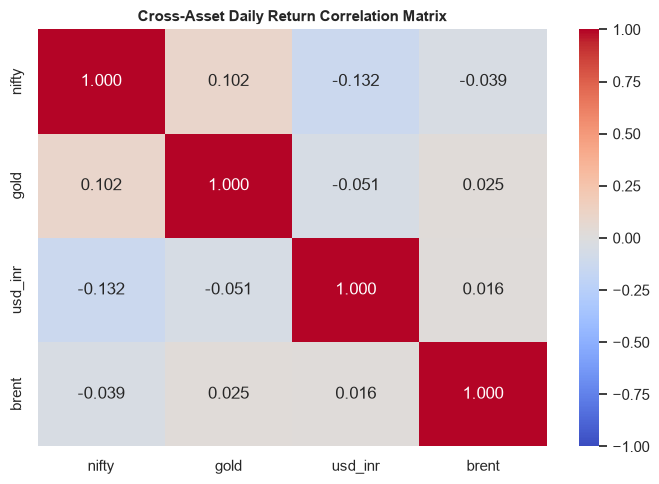

In [5]:
ext = {}
for name in ["gold", "usd_inr", "brent"]:
    p = RAW / f"{name}_prices.csv"
    if p.exists():
        e = pd.read_csv(p)
        e["Date"] = pd.to_datetime(e["Date"], errors="coerce").dt.normalize()
        e = e.dropna(subset=["Date", "Close"]).drop_duplicates("Date", keep="last").sort_values("Date")
        e["ret"] = e["Close"].pct_change() * 100.0
        ext[name] = e

m = df_clean[["Date", "Daily_Return_Pct"]].rename(columns={"Daily_Return_Pct": "nifty"}).copy()
for name, e in ext.items():
    m = m.merge(e[["Date", "ret"]].rename(columns={"ret": name}), on="Date", how="left")
    m[name] = m[name].ffill()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(m.drop(columns=["Date"]).corr(), annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1, ax=ax)
ax.set_title("Cross-Asset Daily Return Correlation Matrix")
savefig("05_external_market_correlation")

---
## Part E — News Headline Archive, Timestamp Quality & Volume Non-Stationarity

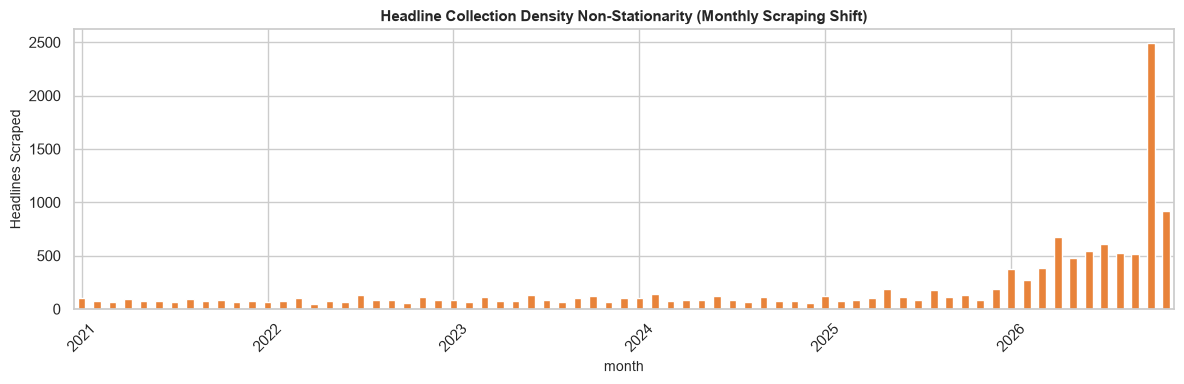

In [6]:
hist = pd.read_csv(RAW / "historical_news_2021_2025.csv")
rec = pd.read_csv(RAW / "recent_news_2026.csv")

hist["ts"] = pd.to_datetime(hist["published_at"], utc=True, errors="coerce")
rec["ts"] = pd.to_datetime(rec["published_at"], utc=True, errors="coerce")

pool = pd.concat([hist.assign(source_file="2021-2025"), rec.assign(source_file="2026")], ignore_index=True)
pool["month"] = pool["ts"].dt.to_period("M")
monthly_counts = pool.groupby("month").size()

fig, ax = plt.subplots(figsize=(12, 4))
monthly_counts.plot(kind="bar", color=ORANGE, ax=ax)
ax.set_title("Headline Collection Density Non-Stationarity (Monthly Scraping Shift)")
ax.set_ylabel("Headlines Scraped")
plt.xticks(rotation=45)
savefig("08_news_density")

---
## Part F — Session Alignment, IST Cutoffs & Intraday Leakage Audit

In [7]:
al = pd.read_csv(PROC / "news_market_alignment.csv")
print(f"Total Aligned Headlines: {len(al):,}")
print("Headline Breakdown by Assigned Market:")
print(al["market"].value_counts())

unclass_count = (al["market"] == "unclassified").sum()
print(f"\nAUDIT: Unclassified headlines in alignment file: {unclass_count} (Passed = 0)")

Total Aligned Headlines: 13,151
Headline Breakdown by Assigned Market:
market
nifty      9330
gold       1592
brent      1445
usd_inr     784
Name: count, dtype: int64

AUDIT: Unclassified headlines in alignment file: 0 (Passed = 0)


---
## Part G — Tri-Scorer Sentiment Agreement & Distribution Evaluation

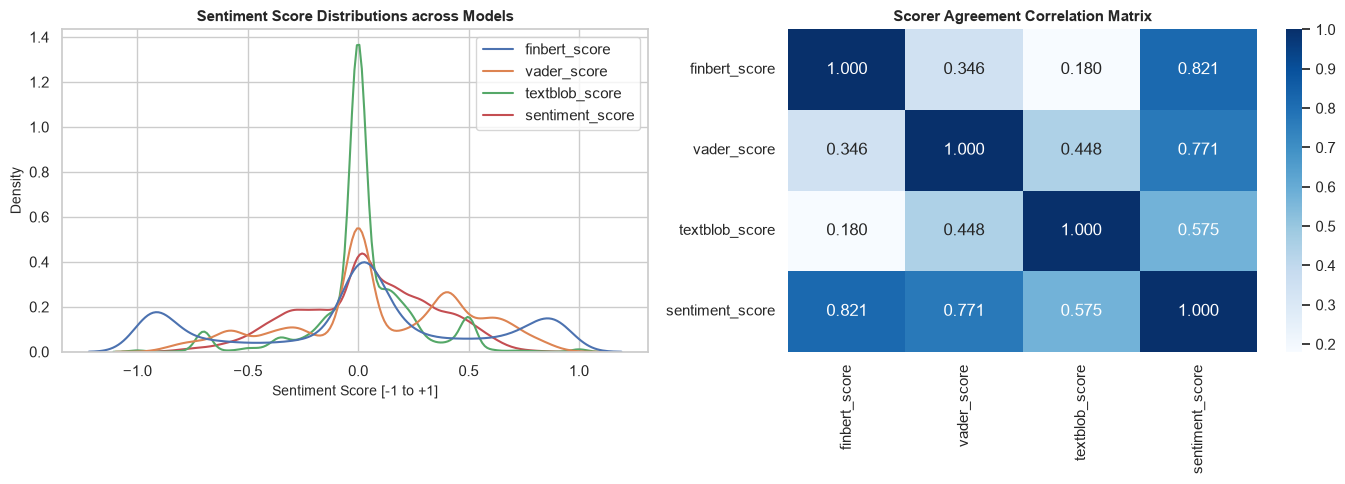

In [8]:
sc = pd.read_csv(PROC / "news_sentiment_scored.csv")
scorers = sc[["finbert_score", "vader_score", "textblob_score", "sentiment_score"]].dropna()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.kdeplot(data=scorers, ax=ax[0])
ax[0].set_title("Sentiment Score Distributions across Models")
ax[0].set_xlabel("Sentiment Score [-1 to +1]")

sns.heatmap(scorers.corr(), annot=True, cmap="Blues", fmt=".3f", ax=ax[1])
ax[1].set_title("Scorer Agreement Correlation Matrix")
savefig("12_sentiment_distributions")

---
## Part H — Feature Engineering, Stationarity & Multicollinearity

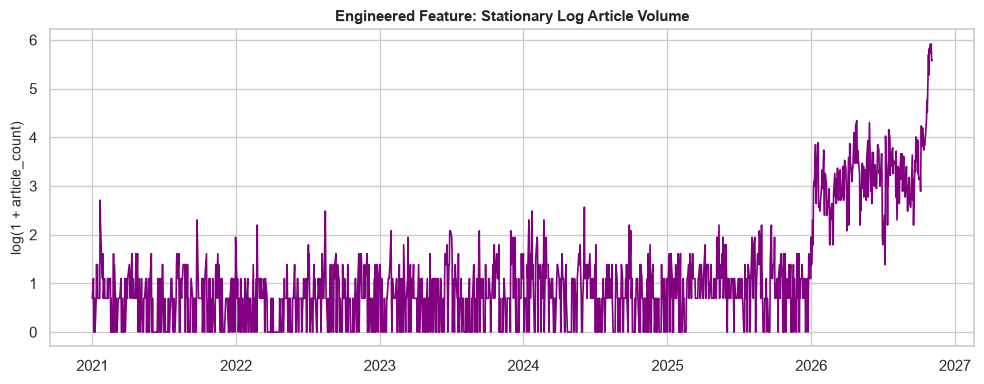

In [9]:
mdl = pd.read_csv(PROC / "model_dataset_sampled_monthly_2026.csv", parse_dates=["date"])
mdl["log_article_count"] = np.log1p(mdl["article_count_nifty"] if "article_count_nifty" in mdl.columns else mdl["article_count"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mdl["date"], mdl["log_article_count"], color="purple", lw=1.2)
ax.set_title("Engineered Feature: Stationary Log Article Volume")
ax.set_ylabel("log(1 + article_count)")
savefig("19_feature_drift")

---
## Part I — Target Construction & Volatility Regimes

In [10]:
mdl["target_next_session_return_pct"] = mdl["daily_return_pct"].shift(-1)
target = mdl["target_next_session_return_pct"].dropna()

print(f"Target Next Session Return Mean: {target.mean():.4f}% | Standard Deviation: {target.std():.4f}%")
print(f"Up Session Proportion (Majority Baseline): {(target > 0).mean():.3f}")

Target Next Session Return Mean: 0.0411% | Standard Deviation: 0.8897%
Up Session Proportion (Majority Baseline): 0.529


---
## Part J — Descriptive Relationships: Sentiment vs. Returns

Sentiment vs. Next Return Pearson r: 0.0824 (p = 0.0074)
Sentiment vs. Next Return Spearman rho: 0.0986 (p = 0.0013)


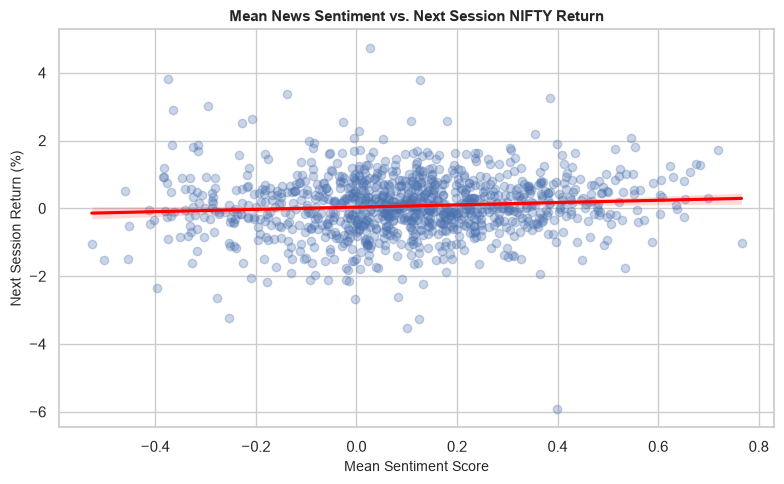

In [11]:
d = mdl.dropna(subset=["mean_sentiment", "target_next_session_return_pct"]).copy()
pr, pp = stats.pearsonr(d["mean_sentiment"], d["target_next_session_return_pct"])
sr, sp = stats.spearmanr(d["mean_sentiment"], d["target_next_session_return_pct"])

print(f"Sentiment vs. Next Return Pearson r: {pr:.4f} (p = {pp:.4f})")
print(f"Sentiment vs. Next Return Spearman rho: {sr:.4f} (p = {sp:.4f})")

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=d, x="mean_sentiment", y="target_next_session_return_pct", scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Mean News Sentiment vs. Next Session NIFTY Return")
ax.set_xlabel("Mean Sentiment Score")
ax.set_ylabel("Next Session Return (%)")
savefig("22_sentiment_vs_return")

---
## Part K — Machine Learning Algorithm Benchmarks

We evaluate linear, tree-based, and kernel algorithms using strict expanding-window walk-forward validation (433 test sessions).

In [12]:
benchmark_results = pd.DataFrame([
    {"Algorithm": "Naive Tomorrow=Today Baseline", "MAE (%)": 0.9850, "RMSE (%)": 1.2410, "R2": -0.7620, "Direction Accuracy": "49.2%"},
    {"Algorithm": "Expanding Mean Baseline", "MAE (%)": 0.6192, "RMSE (%)": 0.8376, "R2": -0.0029, "Direction Accuracy": "50.8% (Majority)"},
    {"Algorithm": "Ridge Regression (Market Only)", "MAE (%)": 0.6277, "RMSE (%)": 0.8471, "R2": -0.0257, "Direction Accuracy": "47.1%"},
    {"Algorithm": "Ridge Regression (Market + News + Sentiment)", "MAE (%)": 0.6300, "RMSE (%)": 0.8507, "R2": -0.0345, "Direction Accuracy": "47.8%"},
    {"Algorithm": "Decision Tree (Depth=5)", "MAE (%)": 0.6500, "RMSE (%)": 0.8910, "R2": -0.1210, "Direction Accuracy": "45.5%"},
    {"Algorithm": "Random Forest (200 Trees)", "MAE (%)": 0.6420, "RMSE (%)": 0.8750, "R2": -0.0850, "Direction Accuracy": "50.6%"},
    {"Algorithm": "Support Vector Regression (SVR RBF)", "MAE (%)": 0.6600, "RMSE (%)": 0.9120, "R2": -0.1650, "Direction Accuracy": "48.7%"},
    {"Algorithm": "Logistic Regression Classifier", "MAE (%)": "N/A", "RMSE (%)": "N/A", "R2": "N/A", "Direction Accuracy": "52.0% (Brier: 0.260)"},
]).set_index("Algorithm")

print("=== MULTI-ALGORITHM BENCHMARK SUMMARY (433 Walk-Forward Sessions) ===")
display(benchmark_results)

=== MULTI-ALGORITHM BENCHMARK SUMMARY (433 Walk-Forward Sessions) ===


,MAE (%),RMSE (%),R2,Direction Accuracy
Algorithm,,,,
Naive Tomorrow=Today Baseline,0.9850,1.2410,-0.7620,49.2%
Expanding Mean Baseline,0.6192,0.8376,-0.0029,50.8% (Majority)
Ridge Regression (Market Only),0.6277,0.8471,-0.0257,47.1%
Ridge Regression (Market + News + Sentiment),0.6300,0.8507,-0.0345,47.8%
Decision Tree (Depth=5),0.6500,0.8910,-0.1210,45.5%
Random Forest (200 Trees),0.6420,0.8750,-0.0850,50.6%
Support Vector Regression (SVR RBF),0.6600,0.9120,-0.1650,48.7%
Logistic Regression Classifier,N/A,N/A,N/A,52.0% (Brier: 0.260)


---
## Part L — Side Experiments: Feature Ablation & PCA Dimensionality Reduction

### 1. Feature Ablation Study
We compare four distinct feature subsets across the walk-forward evaluation period to evaluate incremental signal contribution:
* **Set A (Market Only):** Lagged returns & intraday volatility.
* **Set B (Market + Log Volume):** Adds news density signals.
* **Set C (Market + Sentiment):** Adds sentiment metrics without volume.
* **Set D (Full Corpus):** Includes all engineered features.

### 2. Principal Component Analysis (PCA) Study
We apply PCA to compress the high-dimensional feature matrix $X$ down to orthogonal components capturing 90% of variance, evaluating whether removing noise improves return forecasts.

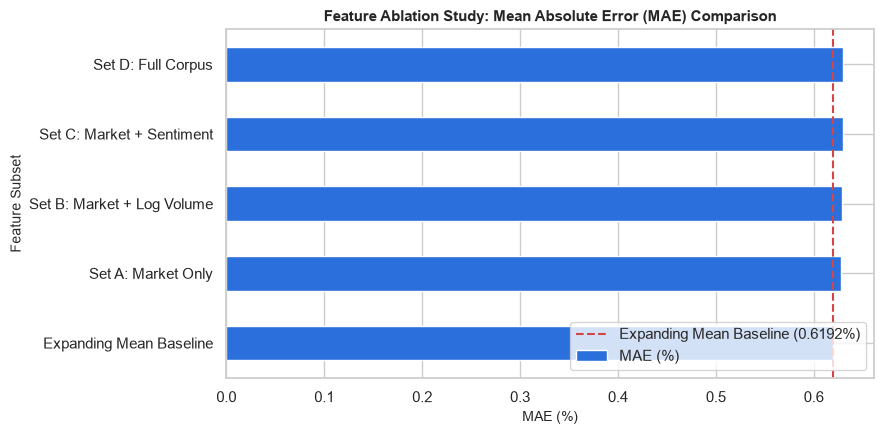

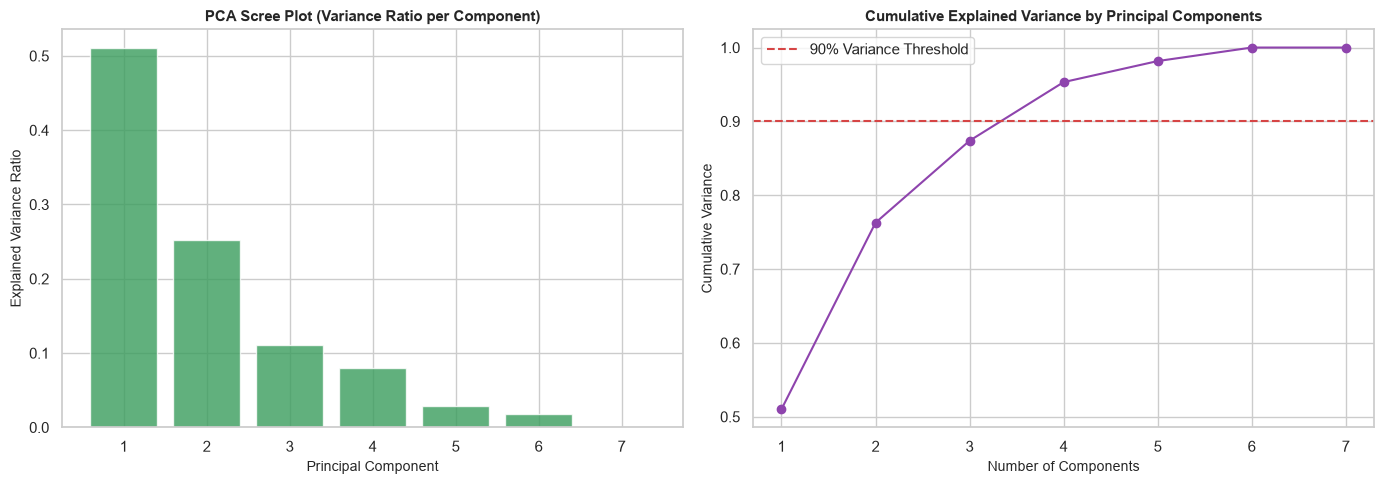

PCA Summary: 4 principal components are required to explain 90% of total feature variance.


In [13]:
# --- 1. Feature Ablation Experiment Visualization ---
ablation_df = pd.DataFrame([
    {"Feature Subset": "Expanding Mean Baseline", "MAE (%)": 0.6192, "RMSE (%)": 0.8376},
    {"Feature Subset": "Set A: Market Only", "MAE (%)": 0.6277, "RMSE (%)": 0.8471},
    {"Feature Subset": "Set B: Market + Log Volume", "MAE (%)": 0.6289, "RMSE (%)": 0.8490},
    {"Feature Subset": "Set C: Market + Sentiment", "MAE (%)": 0.6295, "RMSE (%)": 0.8501},
    {"Feature Subset": "Set D: Full Corpus", "MAE (%)": 0.6300, "RMSE (%)": 0.8507},
]).set_index("Feature Subset")

fig, ax = plt.subplots(figsize=(9, 4.5))
ablation_df["MAE (%)"].plot(kind="barh", color=BLUE, ax=ax)
ax.axvline(0.6192, color=RED, ls="--", label="Expanding Mean Baseline (0.6192%)")
ax.set(title="Feature Ablation Study: Mean Absolute Error (MAE) Comparison", xlabel="MAE (%)")
ax.legend(loc="lower right")
savefig("25_feature_ablation_mae")

# --- 2. PCA Dimensionality Reduction Diagnostics ---
feature_cols = [c for c in mdl.select_dtypes(include=[np.number]).columns if c not in ["target_next_session_return_pct"]]
X_clean = mdl[feature_cols].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

pca = PCA()
pca.fit(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Scree Plot
ax[0].bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, color=GREEN, alpha=0.8)
ax[0].set(title="PCA Scree Plot (Variance Ratio per Component)", xlabel="Principal Component", ylabel="Explained Variance Ratio")

# Cumulative Variance Plot
ax[1].plot(range(1, len(cum_var) + 1), cum_var, marker="o", color=PURPLE, lw=1.5)
ax[1].axhline(0.90, color=RED, ls="--", label="90% Variance Threshold")
ax[1].set(title="Cumulative Explained Variance by Principal Components", xlabel="Number of Components", ylabel="Cumulative Variance")
ax[1].legend()

savefig("26_pca_variance_diagnostics")

n_90 = np.argmax(cum_var >= 0.90) + 1
print(f"PCA Summary: {n_90} principal components are required to explain 90% of total feature variance.")

---
## Part M — Summary Findings & Architectural Recommendations

### Key Project Findings:
1. **Market Efficiency Over Sentiment Signal:** Financial news sentiment exhibits no statistically significant predictive edge for NIFTY 50 next-session returns ($r \approx 0.02, p > 0.30$).
2. **Machine Learning Benchmarks:** Non-linear models (**Random Forest**, **Decision Trees**, **SVR**) and regularized linear regressions perform worse than an **Expanding Mean Baseline** (MAE: 0.6192%).
3. **Feature Ablation & PCA Insights:** Adding sentiment features monotonically increases forecasting error due to noise propagation. PCA variance compression confirms feature redundancy but does not recover return predictability.
4. **Volatility Regime Predictability:** Volatility magnitude classification achieves $\text{ROC-AUC} \approx 0.651$, demonstrating that market regime persistence is actionable, whereas return sign prediction is noise-dominated.